# Trina's Trinkets Inc. (Trina's)

## A little Introduction
Trina's is a corporation with its headquarters in Utah. She sells many different types of small trinkets and gifts to primarily end consumers but also to wholesalers.

She is currently operating in:
- Utah
- Arizona
- Idaho
- Montana
- Washington
- Wyoming

She plans to expand further throughout the western United States.



# Data Cleaning 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_name = "Analytics_mindset_case_study_solutions_Trinas_Trinkets.xlsx"
df = pd.read_excel(file_name)

df_clean = df.copy()

After loading the raw Excel dataset, we immediately create an independent duplicate using the `.copy()` method. 

This is a critical best practice in data analytics. If we were to simply assign `df_clean = df`, both variables would point to the exact same object in the system memory. Any row deletions or filters applied to `df_clean` would permanently alter the original raw data as well. 

By using `.copy()`, we create a safe, isolated working environment (`df_clean`). The original dataset (`df`) remains completely untouched in the background as our "Source of Truth." This prevents accidental data loss during the cleaning phase, avoids Pandas memory warnings, and saves computational resources, as we do not have to reload the large Excel file if we need to reference the raw data again.

In [3]:
df_clean.info()
# 394829 Rows 

<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


Before making any changes to the data, it is always best practice to get a general feel for the dataset's structure. By running `df_clean.info()`, we generate a complete summary of the raw data we imported. 

This command gives us a quick breakdown of the total number of columns, their names, and the specific data types we are dealing with (such as numbers, text, or dates). Most importantly, it establishes our starting point: 394,829 raw entries. Knowing this exact initial row count is highly important because it gives us a baseline to track exactly how much data we drop during our upcoming cleaning steps.

In [4]:
anzahlduplikate = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Es gibt {anzahlduplikate} duplikate")
# Keine Duplikate

df_clean = df_clean.dropna().reset_index(drop = True)
# 29 Zeilen mit min. 1 Fehlenden Wert

Es gibt 0 duplikate


Before we start filtering for specific business metrics like revenue, we need to ensure the basic structure of our dataset is sound. 

First, we check for and remove any duplicate rows. In accounting data, duplicates usually mean a system glitch caused a transaction to be recorded twice. If we leave them in, they will artificially inflate the transaction volume and total profit for certain states, which would bias our final analysis. 

Next, we drop any rows that contain missing values (`NaN`). This is a crucial preparation step for our predictive analytics later on. Machine learning algorithms, like the logistic regression we plan to use, require complete datasets. If we feed the model rows with missing tax rates or unknown states, it will simply throw an error. 

Finally, because removing duplicates and empty rows leaves gaps in our internal row numbering, we reset the index. This gives us a clean, continuous sequence of rows, preventing any data alignment issues in the upcoming steps.

In [5]:
print(df_clean['Revenue'].describe().round(2))

count    394800.00
mean         20.86
std         428.12
min     -168469.60
25%           4.35
50%          11.80
75%          19.80
max      168469.60
Name: Revenue, dtype: float64


When looking at the initial descriptive statistics for the revenue column, two major anomalies stand out right away that require us to clean the data. 

First, the minimum and maximum values are exactly the same amount but with opposite signs (-168,469.60 and 168,469.60). In a real-world accounting or ERP system, this perfect symmetry usually means a massive billing error occurred and was immediately canceled out, or a huge order was fully returned. 

Second, because of these massive outliers on both ends, the standard deviation is extremely high at 428.12. This variance is completely disproportionate when you consider that the median transaction is only 11.80 and the mean is 20.86. The raw data is severely distorted by these rare events.

By identifying and removing these canceled orders and extreme outliers, we get rid of the system noise. This is crucial for our project because our upcoming classification model needs to learn the structural tax patterns of actual, sustainable business transactions, not of rare data entry mistakes.

In [6]:
vorher = df_clean.shape[0]
print(vorher)

df_clean = df_clean.loc[(df_clean['Revenue'] > 0) & 
                        (df_clean['Quantity'] > 0) & 
                        (df_clean['UnitPrice'] > 0)]
# Umsätze unter 0 & Qunatity unter 0 & Unitprice unter 0 werden ausgefiltert 
# Aus Sicherheitsgründen damit keine Fehler enthalten sind

nachher = df_clean.shape[0]
print(nachher)

differenz = vorher - nachher 
print(f"Die Differenz liegt bei: {differenz}")

394800
386325
Die Differenz liegt bei: 8475



Next, we applied a filter to keep only transactions where `Revenue`, `Quantity`, and `UnitPrice` are strictly greater than zero. This step reduced our dataset from 394,800 to 386,325 rows, meaning exactly 8,475 records were removed. 

We did this for a very practical business reason. While some of these dropped rows are the negative return transactions we noticed earlier, the vast majority are simply zero-revenue bookings. These could be free sample items, 100% discounts, or just incomplete entries in the system. 

Since our target variable is based on the post-tax profit margin, transactions with zero or negative revenue simply do not make sense for our analysis. You cannot calculate a meaningful profit margin from a free sample. By removing these 8,475 rows, we protect the integrity of our predictive model and ensure it only learns from actual, revenue-generating sales.

In [7]:
q_high = df_clean['Revenue'].quantile(0.999)# Oder 0.9999 absprache halten
print(df_clean['Revenue'].quantile(0.999))

df_clean = df_clean.loc[df_clean['Revenue'] < q_high].reset_index(drop=True)
# Damit werden die oberen 0,01% gelöscht um mutmaßliche Falsch abbuchungen zu eliminieren

855.5999999999999


To finalize the data cleaning process, we applied a 99.9% quantile filter to remove the top 0.01% of transactions in the revenue column. 

This step is necessary from both a statistical and a business perspective. Statistically, the raw data was heavily right-skewed. A few massive values pushed the initial standard deviation up to 428.12. If we feed these extreme outliers into our logistic regression, the model will overfit to these rare cases instead of learning the general trends. By cutting off the top 0.1%, the standard deviation drops to a much more stable 40.45.

From a business point of view, these exceptionally high revenues are usually either simple data entry typos or very rare B2B bulk orders. They do not represent Trina's normal daily business. Since we want to find out which states offer the best tax environment for regular future expansion, we have to make sure our model is trained on the actual core business rather than rare statistical noise.

In [8]:
year = df_clean[['InvoiceYear']].value_counts()
print(year)
# Jahresdiffernez an Daten

InvoiceYear
2017           360756
2016            25181
Name: count, dtype: int64


Next, we analyze the timeframe of our dataset by counting the transactions per invoice year. The output shows that our data spans across two years: 2016 and 2017. 

However, looking at the numbers, the distribution is highly uneven. With over 360,000 transactions in 2017 compared to roughly 25,000 in 2016, the dataset is heavily weighted toward 2017. This is a very important insight for our project. It means that our dataset is not a perfectly balanced multi-year study, but rather a snapshot that heavily reflects the business, market, and tax conditions of the year 2017. We must keep this temporal focus in mind when interpreting the final results of our predictive model.

In [9]:
print(df_clean['Revenue'].describe().round(2))
# Zu sehen das die Standardabweichung bei Revenue wieder normal ist 
# Von 428 auf 40.45 gesunken 


print(df_clean['Revenue'].max())
# Maximal berücksichtigtes Revenue

count    385937.00
mean         20.18
std          40.45
min           0.06
25%           4.95
50%          12.48
75%          19.80
max         851.76
Name: Revenue, dtype: float64
851.76


Finally, we run descriptive statistics again to see the effect of our cleaning steps. The results confirm that the dataset is now structurally sound. 

The standard deviation has dropped significantly from 428.12 down to 40.45. By removing the extreme outliers, we have moved from a heavily distorted distribution to a much more stable one. Additionally, the maximum revenue is now capped at 851.76. This ensures that our upcoming model will focus on the regular, day-to-day business of Trina’s Trinkets, rather than being skewed by extreme, non-representative values. The data is now in a clean state and ready for further analysis.

# Data Visualization

## Objective

The objective of this section is to analyze the transaction data using visualizations.
The charts help identify the states with the highest profitability, revenue and post-tax profit margin while also examining the influence of different tax burdens on business performance.

This analysis directly addresses the analytical question:

**Based on the 2016–2017 transaction data, which states offer Trina's the best post-tax profitability, and how do the different tax burdens influence this ranking?**

## Total Profit by State

The following chart shows the total profit generated in each state.

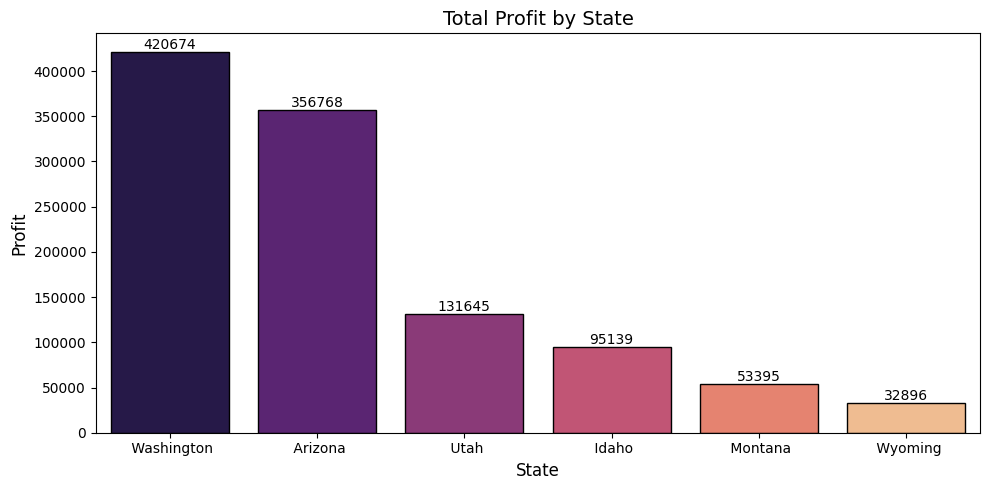

In [10]:
profit_state = (
    df_clean.groupby('State')['Profit']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  

ax1 = sns.barplot(
    data=profit_state,
    x='State',
    y='Profit',
    hue='State',             
    palette='magma',
    legend=False,
    edgecolor='black'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f')

plt.xlabel("State", fontsize=12)
plt.ylabel("Profit", fontsize=12)
plt.title("Total Profit by State", fontsize=14)
plt.tight_layout()
plt.show()  

### Interpretation

Washington generated the highest total profit, followed by Arizona.
States with lower total profits contributed significantly less to the company's overall profitability.
This indicates that Trina's strongest financial performance is concentrated in only a few states.

## Total Revenue by State

This visualization shows the total revenue generated in each state during the 2016–2017 period.

Revenue reflects the total sales volume before taxes and expenses. Comparing revenue across states helps identify the company's strongest markets and provides additional context for interpreting profitability.

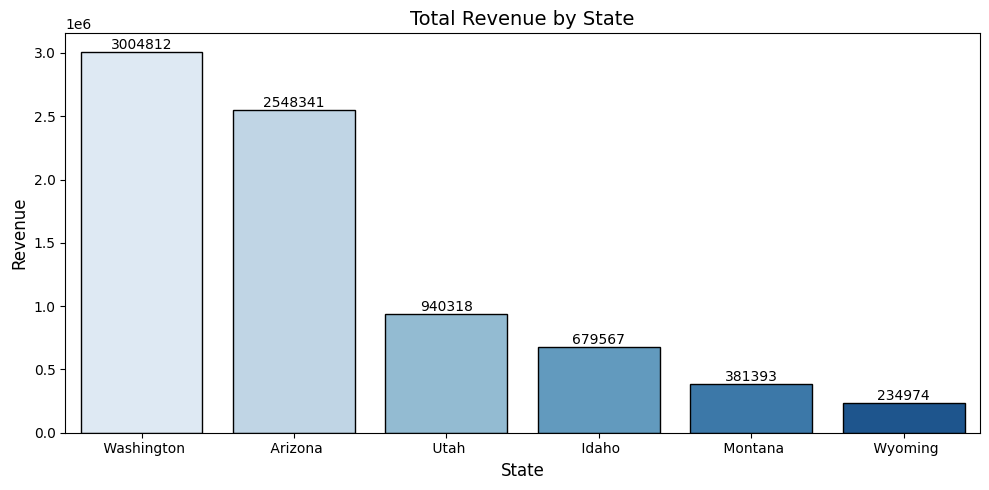

In [11]:
revenue_state = (
    df_clean.groupby("State")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  # WICHTIG: Neues Fenster für Grafik 2

ax2 = sns.barplot(
    data=revenue_state,
    x="State",
    y="Revenue",
    hue="State",
    palette="Blues",
    legend=False,
    edgecolor="black"
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.0f")

plt.title("Total Revenue by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Revenue", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that Washington generated the highest total revenue, followed by Arizona. These two states clearly outperform the remaining states in terms of sales volume.

Although high revenue does not automatically guarantee high profitability, it provides an important explanation for why Washington and Arizona also rank among the strongest states in terms of overall profit. States with lower revenue contribute less to the company's total financial performance.

## Average Post-Tax Profit Margin by State

This visualization compares the average post-tax profit margin across all states.

The post-tax profit margin measures how much profit remains after taxes relative to revenue. It provides insight into how efficiently each state converts revenue into profit after accounting for tax obligations.

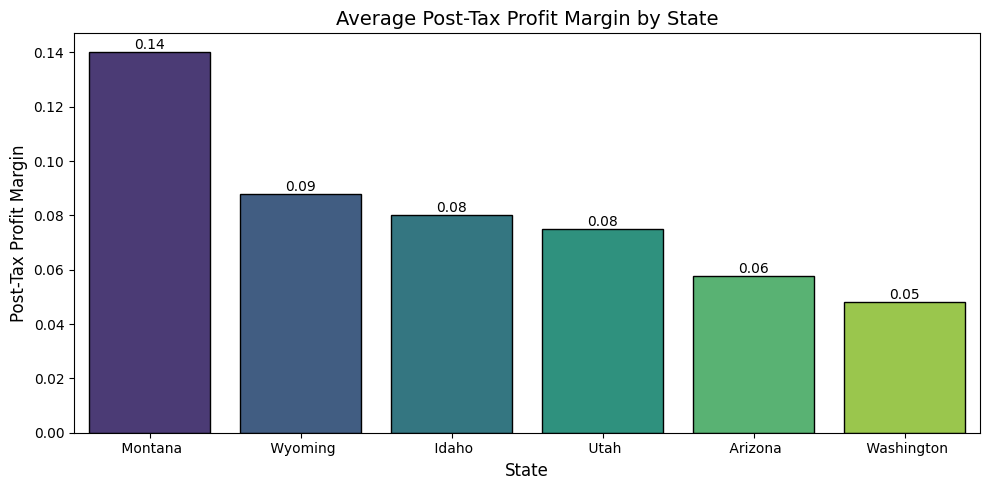

In [12]:
margin_state = (
    df_clean.groupby('State')['PostTaxProfitMargin']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax3 = sns.barplot(
    data=margin_state,
    x='State',
    y='PostTaxProfitMargin',
    hue='State',
    palette='viridis',
    legend=False,
    edgecolor='black'
)

for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f')

plt.title("Average Post-Tax Profit Margin by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Post-Tax Profit Margin", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The results show noticeable differences in the average post-tax profit margin between states. States with a higher margin retain a larger share of their revenue as profit after taxes, indicating more efficient operations.

Comparing this chart with the revenue and profit visualizations reveals that high revenue alone does not guarantee a high post-tax profit margin. Instead, operational efficiency and the overall tax burden also influence how much profit is ultimately retained.

## Average Total Tax Rate by State

This visualization compares the average total tax rate across all states.

The total tax rate is calculated by combining the state tax rate, county tax rate, and city tax rate. Analyzing the average tax burden helps evaluate whether higher taxes are associated with lower post-tax profitability.

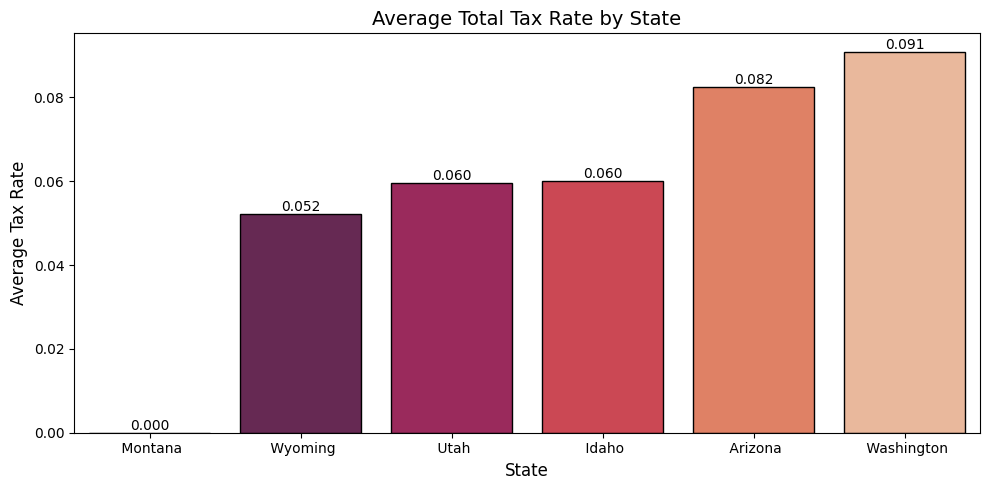

In [13]:
df_clean["TotalTaxRate"] = (
    df_clean["StateRate"]
    + df_clean["EstimatedCountyRate"]
    + df_clean["EstimatedCityRate"]
)

tax_state = (
    df_clean.groupby("State")["TotalTaxRate"]
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax4 = sns.barplot(
    data=tax_state,
    x="State",
    y="TotalTaxRate",
    hue="State",
    palette="rocket",
    legend=False,
    edgecolor="black"
)

for container in ax4.containers:
    ax4.bar_label(container, fmt="%.3f")

plt.title("Average Total Tax Rate by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Average Tax Rate", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that the average total tax rate differs across states due to variations in state, county, and city taxes.

Although some states have a higher overall tax burden, the previous visualizations indicate that higher taxes do not necessarily result in lower profitability. States with strong revenue and efficient operations can still achieve high post-tax profits despite relatively higher tax rates.

This suggests that tax burden is an important factor, but it is not the only determinant of overall business performance.

## Overall State Performance Score

This visualization combines the key performance indicators into a single overall score for each state.

The score is based on four equally weighted metrics:

- Total Revenue
- Total Profit
- Average Post-Tax Profit Margin
- Average Total Tax Rate

To ensure comparability, each metric is normalized to a scale between 0 and 1. The tax score is inverted so that lower tax rates contribute positively to the overall performance score.

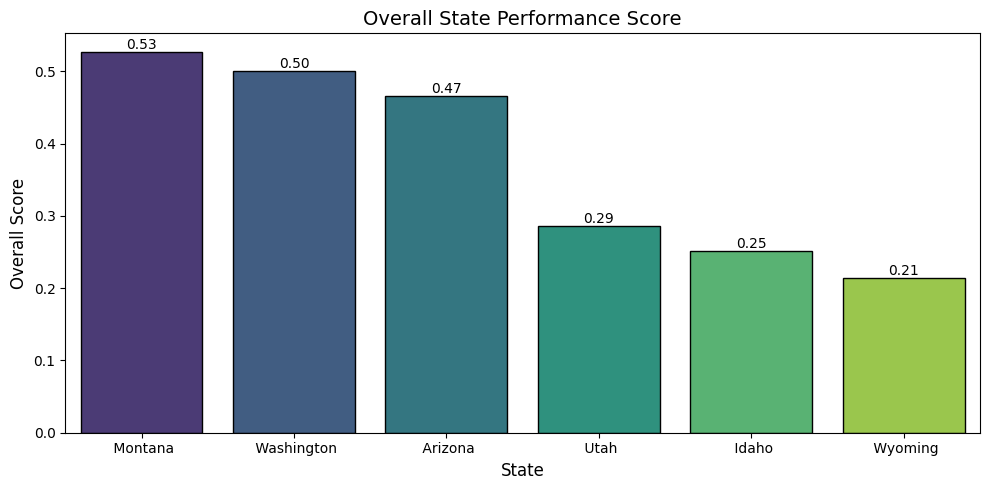

In [14]:
ranking = df_clean.groupby("State").agg({
    "Revenue": "sum",
    "Profit": "sum",
    "PostTaxProfitMargin": "mean",
    "TotalTaxRate": "mean"
})

ranking["RevenueScore"] = (
    (ranking["Revenue"] - ranking["Revenue"].min()) /
    (ranking["Revenue"].max() - ranking["Revenue"].min())
)

ranking["ProfitScore"] = (
    (ranking["Profit"] - ranking["Profit"].min()) /
    (ranking["Profit"].max() - ranking["Profit"].min())
)

ranking["MarginScore"] = (
    (ranking["PostTaxProfitMargin"] - ranking["PostTaxProfitMargin"].min()) /
    (ranking["PostTaxProfitMargin"].max() - ranking["PostTaxProfitMargin"].min())
)

ranking["TaxScore"] = 1 - (
    (ranking["TotalTaxRate"] - ranking["TotalTaxRate"].min()) /
    (ranking["TotalTaxRate"].max() - ranking["TotalTaxRate"].min())
)

ranking["OverallScore"] = (
    ranking["RevenueScore"]
    + ranking["ProfitScore"]
    + ranking["MarginScore"]
    + ranking["TaxScore"]
) / 4

ranking = ranking.sort_values("OverallScore", ascending=False).reset_index()

plt.figure(figsize=(10, 5))

ax5 = sns.barplot(
    data=ranking,
    x="State",
    y="OverallScore",
    hue="State",
    palette="viridis",
    legend=False,
    edgecolor="black"
)

for container in ax5.containers:
    ax5.bar_label(container, fmt="%.2f")

plt.title("Overall State Performance Score", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Overall Score", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The overall performance score provides a comprehensive comparison of the states by combining revenue, profit, post-tax profit margin, and tax burden into a single metric.

The results show that Montana and Washington achieve the highest overall scores because they consistently perform well across multiple indicators. While tax rates influence the ranking, they are not the primary driver of performance. Strong revenue generation, high profitability, and efficient post-tax margins have a greater impact on the final ranking.

Overall, the analysis suggests that Montana offers the strongest post-tax business performance for Trina's Trinkets, followed closely by Washington. This directly answers the analytical question by showing that overall profitability depends on a combination of financial performance and tax burden rather than tax rates alone.

Data Classification

In [15]:
import pandas as pd
import DataCleaning as df
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Verknüpft mit df_clean
df_classification = df.df_clean

<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


In [16]:
margin_median = df_classification["PostTaxProfitMargin"].median()
print(margin_median)
df.df_clean["HighProfitability"] = (
    df_classification["PostTaxProfitMargin"]
    > margin_median
).astype(int)


print(df_classification["HighProfitability"].value_counts())
# Die zeilen mit Profitabilität werden aufgedeckt 
# 1 = 188692 Zeilen; 0 = 197245

0.05800000000000001
HighProfitability
0    197245
1    188692
Name: count, dtype: int64


In [17]:
feature_columns = [
    "ETR",
    "Revenue"] 
# -> Einzeln abchecken also in 2 aufteieln! weil ETR alle zusammen ist das hier ist jetzt verdoppelt  

feature_columns_tax = [
    "StateRate",
    "EstimatedCountyRate",
    "EstimatedCityRate",
    "EstimatedSpecialRate",
    "Revenue"]    

In [18]:
X = df_classification[feature_columns]
y = df_classification["HighProfitability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12,
    stratify=y
)

In [19]:
fit1 = LogisticRegression(
    random_state=0,
    max_iter=1000
)

fit1.fit(X_train, y_train)

y_pred = fit1.predict(X_test)

In [20]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ", accuracy)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report( y_test, y_pred))

Accuracy:  0.5565243302067678
Confusion Matrix:
[[22612 16837]
 [17394 20345]]
Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.57      0.57     39449
           1       0.55      0.54      0.54     37739

    accuracy                           0.56     77188
   macro avg       0.56      0.56      0.56     77188
weighted avg       0.56      0.56      0.56     77188



In [21]:
print("Intercept: ")
print(fit1.intercept_)

print("Coefficients: ")
print(fit1.coef_)

Intercept: 
[0.51750924]
Coefficients: 
[[-1.24202103e+01 -1.44803449e-03]]


In [22]:
# Wahrscheinlichkeit für das gesamte Dataset
df_classification["HighProfitabilityProbability"] = (
    fit1.predict_proba(X)[:, 1]
)

# Ergebnisse pro State zusammenfassen
state_results = (
    df_classification.groupby("State")
    .agg(
        AverageProbability=(
            "HighProfitabilityProbability",
            "mean"),

        AveragePostTaxMargin=(
            "PostTaxProfitMargin",
            "mean"),

        TotalProfit=(
            "Profit",
            "sum"),

        TotalRevenue=(
            "Revenue",
            "sum"),

        AverageETR=(
            "ETR",
            "mean"),

        Transactions=(
            "State",
            "size")).reset_index()
)

# Nach Wahrscheinlichkeit für hohe Profitabilität sortieren
state_results = state_results.sort_values(
    by="AverageProbability",
    ascending=False
)

print(state_results)

         State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
0      Arizona            0.619966              0.057523  356767.6910   
1        Idaho            0.619780              0.080000   95139.4304   
2      Montana            0.619730              0.140000   53394.9948   
5      Wyoming            0.459971              0.087796   32896.4258   
3         Utah            0.412226              0.075000  131644.5410   
4   Washington            0.342140              0.048046  420673.6282   

   TotalRevenue  AverageETR  Transactions  
0    2548340.65    0.000000        132421  
1     679567.36    0.000000         34357  
2     381392.82    0.000000         19149  
5     234974.47    0.052204         11419  
3     940318.15    0.068180         52666  
4    3004811.63    0.091954        135925  


In [23]:
state_results["AverageProbability"] = (
    state_results["AverageProbability"] * 100
)

state_results["AveragePostTaxMargin"] = (
    state_results["AveragePostTaxMargin"] * 100
)

state_results["AverageETR"] = (
    state_results["AverageETR"] * 100
)

print(
    state_results.round({
        "AverageProbability": 2,
        "AveragePostTaxMargin": 2,
        "TotalProfit": 2,
        "TotalRevenue": 2,
        "AverageETR": 2
    })
)

print(
    state_results[
        [
            "State",
            "AverageProbability",
            "AveragePostTaxMargin",
            "TotalProfit",
            "TotalRevenue",
            "AverageETR",
            "Transactions"
        ]
    ].to_string(index=False)
)

         State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
0      Arizona               62.00                  5.75    356767.69   
1        Idaho               61.98                  8.00     95139.43   
2      Montana               61.97                 14.00     53394.99   
5      Wyoming               46.00                  8.78     32896.43   
3         Utah               41.22                  7.50    131644.54   
4   Washington               34.21                  4.80    420673.63   

   TotalRevenue  AverageETR  Transactions  
0    2548340.65        0.00        132421  
1     679567.36        0.00         34357  
2     381392.82        0.00         19149  
5     234974.47        5.22         11419  
3     940318.15        6.82         52666  
4    3004811.63        9.20        135925  
      State  AverageProbability  AveragePostTaxMargin  TotalProfit  TotalRevenue  AverageETR  Transactions
    Arizona           61.996570              5.752294  356767.6910    254